# Quantum phase transitions with Qiskit
### Finding the ground state of the Ising chain with a variational quantum algorithm

In this tutorial you will use a quantum algorithm, the **variational quantum eigensolver (VQE)**, to study a **quantum phase transition** in a chain of qubits. You will:

1. write the Hamiltonian of the Ising model with Qiskit;
2. find its lowest-energy state, the **ground state**, with VQE;
3. measure how magnetized the chain is, and watch the phase transition appear, and get sharper, as the chain gets longer.

**What you need to know:** basic Python, and the basics of qubits and of the Pauli matrices $X$ and $Z$.
**Software:** Qiskit 2.x, NumPy, SciPy and Matplotlib.

*Adapted from the PennyLane demo [“Seeing quantum phase transitions with quantum computers”](https://pennylane.ai/qml/demos/tutorial_quantum_phase_transitions) by Damian Pope and Tirth Shah ([source](https://github.com/PennyLaneAI/demos)). Rewritten for Qiskit and adapted for this hackaton. The figures are from the original demo.*

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.sparse.linalg import eigsh

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp, Statevector

print("Qiskit version:", qiskit.__version__)

# One color and one marker per chain length, used in every figure
SIZE_COLORS = {4: "#2a78d6", 5: "#eb6834", 6: "#1baf7a", 8: "#eda100", 10: "#e87ba4"}
SIZE_MARKERS = {4: "o", 5: "x", 6: "s", 8: "^", 10: "D"}
plt.rcParams.update({"figure.figsize": (6.4, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

Qiskit version: 2.6.1


## 1. What is a phase transition?

A **phase transition** is an abrupt change in the properties of a system when one of its parameters is varied. Water freezing into ice when the temperature drops below 0 °C is the everyday example. Phase transitions appear everywhere in physics, from magnets and superconductors to the early universe.

A **quantum** phase transition happens at zero temperature. It is driven not by heat but by *quantum fluctuations*, a consequence of Heisenberg's uncertainty principle: changing a parameter in the Hamiltonian changes the nature of the ground state. For large systems these transitions are very hard to compute on classical computers, which is one reason why physicists want to study them on quantum computers.

## 2. The Ising model

The simplest Ising model is a chain of $N$ qubits on a line. Think of each qubit as a small magnet (a *spin*) that can point up ($|0\rangle$) or down ($|1\rangle$) along $z$. Each spin interacts with its neighbours on either side.

<center><img src="https://raw.githubusercontent.com/PennyLaneAI/demos/a83efb73d7989aa60917124c25ce0469c02bae02/_static/demonstration_assets/quantum_phase_transitions/Fig_1_Ising_chain.png" width="30%" alt="A chain of qubits, each interacting with its nearest neighbours"></center>

The energy of the chain is given by the Hamiltonian

$$H = -J \sum_{i=0}^{N-2} Z_i Z_{i+1},$$

where $Z_i$ is the Pauli-$Z$ operator acting on qubit $i$ and $J > 0$ is the strength of the interaction. Each term gives $-J$ when two neighbours point the same way and $+J$ when they point opposite ways, so the energy is lowest when all spins agree.

In Qiskit, Hamiltonians are written as sums of *Pauli strings* with `SparsePauliOp`. Note that Qiskit prints the strings with qubit 0 on the **right**: `"IZZ"` means $Z$ on qubits 0 and 1, and nothing (the identity $I$) on qubit 2. The function below also has a second term, the *transverse field*, which we will use later; for now it is switched off ($h_x = 0$).

In [3]:
def ising_hamiltonian(N, J, h_x=0.0):
    # Open chain:  H = -J * sum_i Z_i Z_{i+1}  -  h_x * sum_i X_i
    terms = [("ZZ", [i, i + 1], -J) for i in range(N - 1)]
    if h_x != 0:
        terms += [("X", [i], -h_x) for i in range(N)]
    return SparsePauliOp.from_sparse_list(terms, num_qubits=N)


N = 3
J = 2

H = ising_hamiltonian(N, J)
print(f"H = {H}")

H = SparsePauliOp(['IZZ', 'ZZI'],
              coeffs=[-2.+0.j, -2.+0.j])


## 3. Finding the ground state with VQE

The **ground state** is the state of lowest energy. For three qubits we can guess it, but in general we need an algorithm. The **variational quantum eigensolver (VQE)** works like this:

1. A quantum circuit with adjustable rotation angles $\boldsymbol\theta$ prepares a trial state $|\psi(\boldsymbol\theta)\rangle$. This circuit is called the **ansatz**.
2. The quantum computer measures the energy $E(\boldsymbol\theta) = \langle\psi(\boldsymbol\theta)|H|\psi(\boldsymbol\theta)\rangle$.
3. A classical optimizer changes $\boldsymbol\theta$ to lower the energy, and steps 2 and 3 are repeated.

The **variational principle** guarantees that $E(\boldsymbol\theta)$ is never below the true ground-state energy, so the lowest energy we find is our best estimate of it.

As ansatz we use the **hardware-efficient ansatz** [2], which is easy to run on real devices:

1. three rotations ($R_Z$, $R_X$, $R_Z$) on each qubit, each with its own angle;
2. a CNOT gate between each pair of neighbouring qubits;
3. another three rotations ($R_Z$, $R_X$, $R_Z$) on each qubit.

That makes $6N$ angles in total.

In [4]:
def create_ansatz(N):
    # Hardware-efficient ansatz with 6N parameters θ[0], ..., θ[6N-1]
    theta = ParameterVector("θ", 6 * N)
    qc = QuantumCircuit(N)
    # STEP 1: single-qubit rotations on all the qubits
    for i in range(N):
        qc.rz(theta[i], i)
        qc.rx(theta[N + i], i)
        qc.rz(theta[2 * N + i], i)
    # STEP 2: a CNOT gate on each pair of neighbouring qubits
    for i in range(N - 1):
        qc.cx(i, i + 1)
    # STEP 3: single-qubit rotations on all the qubits
    for i in range(N):
        qc.rz(theta[3 * N + i], i)
        qc.rx(theta[4 * N + i], i)
        qc.rz(theta[5 * N + i], i)
    return qc


ansatz = create_ansatz(N)
print(ansatz.draw("text", fold=-1))

     ┌──────────┐┌──────────┐┌──────────┐     ┌──────────┐┌───────────┐┌───────────┐             
q_0: ┤ Rz(θ[0]) ├┤ Rx(θ[3]) ├┤ Rz(θ[6]) ├──■──┤ Rz(θ[9]) ├┤ Rx(θ[12]) ├┤ Rz(θ[15]) ├─────────────
     ├──────────┤├──────────┤├──────────┤┌─┴─┐└──────────┘├───────────┤├───────────┤┌───────────┐
q_1: ┤ Rz(θ[1]) ├┤ Rx(θ[4]) ├┤ Rz(θ[7]) ├┤ X ├─────■──────┤ Rz(θ[10]) ├┤ Rx(θ[13]) ├┤ Rz(θ[16]) ├
     ├──────────┤├──────────┤├──────────┤└───┘   ┌─┴─┐    ├───────────┤├───────────┤├───────────┤
q_2: ┤ Rz(θ[2]) ├┤ Rx(θ[5]) ├┤ Rz(θ[8]) ├────────┤ X ├────┤ Rz(θ[11]) ├┤ Rx(θ[14]) ├┤ Rz(θ[17]) ├
     └──────────┘└──────────┘└──────────┘        └───┘    └───────────┘└───────────┘└───────────┘


### Measuring energies and optimizing the angles

- **Measuring the energy.** In Qiskit, expectation values like $E(\boldsymbol\theta)$ are computed by an **Estimator**. You give it a circuit, an observable (here $H$) and values for the angles. We use `StatevectorEstimator`, which simulates the circuit exactly on your computer; Section 9 explains what changes on a real quantum computer.
- **Which way is downhill?** The optimizer also needs the *gradient*: how the energy changes when each angle changes. On a quantum computer this is obtained with the **parameter-shift rule**: each derivative is the difference between two energies, measured with that angle shifted by $+\pi/2$ and $-\pi/2$. We send all these circuits to the Estimator at once.
- **The optimizer.** We use **L-BFGS-B** from SciPy, a standard method for smooth functions. It uses the gradients it has already seen to choose good steps, and stops when the energy can no longer be lowered.
- **Several starting points.** An optimizer can get stuck in a *local minimum*, a valley that is not the lowest one. To be safe, we start it from three random sets of angles and keep the result with the lowest energy.

> *For the curious:* for rotation gates such as $R_X$ and $R_Z$, the parameter-shift rule is exact:
> $\dfrac{\partial E}{\partial \theta_k} = \dfrac{E(\boldsymbol\theta + \frac{\pi}{2}\mathbf e_k) - E(\boldsymbol\theta - \frac{\pi}{2}\mathbf e_k)}{2}$.

In [5]:
estimator = StatevectorEstimator()


def make_cost_function(ansatz, hamiltonian):
    # Returns a function params -> (energy, gradient), with the gradient from the parameter-shift rule
    n_params = ansatz.num_parameters
    shifts = (np.pi / 2) * np.eye(n_params)

    def energy_and_gradient(params):
        # all circuits in one batch: the angles themselves, then each angle shifted by +π/2, then by -π/2
        batch = np.vstack([params, params + shifts, params - shifts])
        evs = estimator.run([(ansatz, hamiltonian, batch)]).result()[0].data.evs
        return evs[0], 0.5 * (evs[1:n_params + 1] - evs[n_params + 1:])

    return energy_and_gradient


def run_vqe(ansatz, hamiltonian, rng, n_starts=3):
    # VQE with SciPy's L-BFGS-B, started from n_starts random sets of angles.
    # Returns all runs, the one with the lowest energy first. Each run records its start number,
    # the optimized angles, the energy after every iteration, the final energy and the number of iterations.
    cost = make_cost_function(ansatz, hamiltonian)
    runs = []
    for start in range(n_starts):
        params = rng.uniform(0, 2 * np.pi, ansatz.num_parameters)
        energy = [estimator.run([(ansatz, hamiltonian, params)]).result()[0].data.evs.item()]
        result = minimize(cost, params, jac=True, method="L-BFGS-B",
                          callback=lambda intermediate_result: energy.append(intermediate_result.fun))
        runs.append({"start": start, "params": result.x, "energy": energy, "E": result.fun, "iterations": result.nit})
    return sorted(runs, key=lambda run: run["E"])

### A first example: three qubits

Let's find the ground state for $N = 3$ and $J = 2$. The random starting angles come from a generator with a fixed *seed*, so you get the same numbers every time you run the notebook.

In [6]:
rng = np.random.default_rng(3)  # fixed seed: reproducible starting angles

runs = run_vqe(ansatz, H, rng)
energy = runs[0]["energy"]  # energy history of the best run, plotted below

for run in sorted(runs, key=lambda run: run["start"]):
    print(f"start {run['start']}: {run['iterations']:3d} L-BFGS-B iterations, final energy E = {run['E']:.5f}")

start 0:  13 L-BFGS-B iterations, final energy E = -4.00000
start 1:  17 L-BFGS-B iterations, final energy E = -4.00000
start 2:  18 L-BFGS-B iterations, final energy E = -4.00000


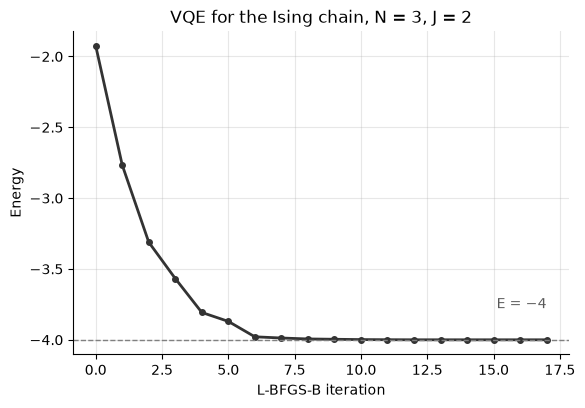

In [7]:
plt.plot(range(len(energy)), energy, color="0.2", lw=2, marker="o", ms=4)
plt.axhline(-4, color="0.5", lw=1, ls="--")
plt.text(len(energy) - 1, -3.8, "E = −4", ha="right", va="bottom", color="0.35")
plt.xlabel("L-BFGS-B iteration")
plt.ylabel("Energy")
plt.title("VQE for the Ising chain, N = 3, J = 2")
plt.show()

All three starts reach $E = -4$, in fewer than 20 iterations. Is that right? Take the first term of the Hamiltonian, $-2\,Z_0 Z_1$. If the first two qubits are both in $|0\rangle$, then $\langle Z_0 Z_1\rangle = (+1)(+1) = +1$, and the term contributes $-2$. If the last two qubits are also in $|0\rangle$, the second term contributes another $-2$, so $E = -4$. With all qubits in $|1\rangle$ the energy is $-4$ as well. VQE has found the ground state.

## 4. Adding a transverse field

Now we add a magnetic field along $x$, perpendicular to the $z$ direction of the interaction. It is called a **transverse field**, and it adds the term $-h_x \sum_i X_i$:

<img src="https://raw.githubusercontent.com/PennyLaneAI/demos/a83efb73d7989aa60917124c25ce0469c02bae02/_static/demonstration_assets/quantum_phase_transitions/Fig_2_transverse_Ising.png" width="50%" alt="The Ising chain in a transverse magnetic field">

$$H = -J \sum_{i=0}^{N-2} Z_i Z_{i+1} \;-\; h_x \sum_{i=0}^{N-1} X_i .$$

The two terms compete, like a tug of war:

- When $J \gg h_x$, the interaction wins and the spins all align along $z$. This is the **ordered** phase.

  <img src="https://raw.githubusercontent.com/PennyLaneAI/demos/a83efb73d7989aa60917124c25ce0469c02bae02/_static/demonstration_assets/quantum_phase_transitions/Fig_3_ground_state_J_large.png" width="70%" alt="Ground state for J much larger than h_x: all spins along z">

- When $h_x \gg J$, the field wins and every spin points along $x$, parallel to the field. Along $z$ they are then completely random. This is the **disordered** phase.

  <img src="https://raw.githubusercontent.com/PennyLaneAI/demos/a83efb73d7989aa60917124c25ce0469c02bae02/_static/demonstration_assets/quantum_phase_transitions/Fig_4_ground_state_h_large.png" width="70%" alt="Ground state for h_x much larger than J: all spins along x">

For an infinitely long chain, the switch between the two phases happens sharply at $J/h_x = 1$ [3, 4]. This is the quantum phase transition we want to see.

## 5. Measuring order: the magnetization

To tell the two phases apart we look at the **magnetization**, the average of all the $Z_i$:

$$M = \frac{1}{N} \sum_i Z_i .$$

If you measure all the qubits, $M$ is close to $+1$ or $-1$ in the ordered phase (almost all spins agree), and close to $0$ in the disordered phase (the spins are random).

**A subtlety.** For a chain of finite length, the ordered ground state is not "all up" or "all down", but a *superposition* of the two, roughly $(|00\cdots0\rangle + |11\cdots1\rangle)/\sqrt2$. Each measurement finds an ordered chain, but up and down are equally likely, so the *average* $\langle M\rangle$ is zero, at every $J$. That's why we measure the average of $M^2$ instead: squaring removes the sign. Its square root, $\sqrt{\langle M^2\rangle}$, is the typical size of the magnetization:

- it is close to 1 in the ordered phase;
- it is small in the disordered phase, but not exactly zero for a short chain: even completely random spins give $\sqrt{\langle M^2\rangle} = 1/\sqrt N$.

$M^2 = \frac{1}{N^2} \sum_{i,j} Z_i Z_j$ is again a sum of Pauli strings, so the Estimator can measure it just like the energy.

For small chains we can also compute everything **exactly**, by writing $H$ as a $2^N \times 2^N$ matrix and finding its lowest eigenvector. This is impossible for large $N$, but here it lets us check the VQE results.

In [8]:
def magnetization_op(N):
    # M = (1/N) * sum_i Z_i
    return SparsePauliOp.from_sparse_list([("Z", [i], 1 / N) for i in range(N)], num_qubits=N)


def magnetization_squared_op(N):
    # M^2 = (1/N^2) * sum_ij Z_i Z_j
    M = magnetization_op(N)
    return (M @ M).simplify()


def exact_ground_state(hamiltonian):
    # Lowest energy and corresponding state, by exact diagonalization of the 2^N x 2^N matrix (small N only)
    values, vectors = eigsh(hamiltonian.to_matrix(sparse=True), k=1, which="SA")
    return values[0], vectors[:, 0]


def exact_rms_magnetization(N, J, h_x=1.0):
    # sqrt(<M^2>) in the exact ground state
    psi = Statevector(exact_ground_state(ising_hamiltonian(N, J, h_x))[1])
    return np.sqrt(psi.expectation_value(magnetization_squared_op(N)).real)


print("M^2 for N = 3:", magnetization_squared_op(3))

M^2 for N = 3: SparsePauliOp(['III', 'IZZ', 'ZIZ', 'ZZI'],
              coeffs=[0.33333333+0.j, 0.22222222+0.j, 0.22222222+0.j, 0.22222222+0.j])


## 6. Scanning $J$ for a chain of 5 qubits

We fix the field at $h_x = 1$ and vary $J$, so that $J/h_x$ goes from 0 (field only) to 7.5 (interaction dominates), with more points around the expected transition at $J = 1$. For each value of $J$ we run VQE (three starts, best one kept) and measure the energy and $\langle M^2\rangle$ of the result in a single Estimator call.

In [9]:
N = 5

# h_x is the strength of the transverse magnetic field
h_x = 1

# the values of J (and therefore of J/h_x) that we scan
J_list = [0.0, 0.25, 0.5, 0.75, 0.9, 1.0, 1.1, 1.25, 1.5, 2.0, 5.0, 7.5]

ansatz_5 = create_ansatz(N)
M2 = magnetization_squared_op(N)
rng = np.random.default_rng(N)  # fixed seed: reproducible starting angles

runs_5, energy_list, m2_list, iterations_list = [], [], [], []
for J in J_list:
    H = ising_hamiltonian(N, J, h_x)
    runs = run_vqe(ansatz_5, H, rng)  # three starts, lowest energy first

    # energy and <M^2> of the best state, from one Estimator call
    E, m2 = estimator.run([(ansatz_5, [H, M2], runs[0]["params"])]).result()[0].data.evs
    runs_5.append(runs)
    energy_list.append(E)
    m2_list.append(m2)
    iterations_list.append(runs[0]["iterations"])

print(f"{'J':>5} {'iterations':>11} {'E':>10} {'sqrt<M2>':>9} {'exact':>7}")
for J, n_it, E, m2 in zip(J_list, iterations_list, energy_list, m2_list):
    print(f"{J:5.2f} {n_it:11d} {E:10.4f} {np.sqrt(m2):9.3f} {exact_rms_magnetization(N, J, h_x):7.3f}")

    J  iterations          E  sqrt<M2>   exact
 0.00          15    -5.0000     0.447   0.447
 0.25         102    -5.0624     0.494   0.497
 0.50          43    -5.2490     0.545   0.558
 0.75          34    -5.5575     0.600   0.633
 0.90          30    -5.7997     0.635   0.682
 1.00          57    -5.9842     0.660   0.716
 1.10          30    -6.1868     0.684   0.749
 1.25          28    -6.5234     0.721   0.794
 1.50         208    -7.1773     0.888   0.856
 2.00         325    -8.8770     0.942   0.927
 5.00          95   -20.3499     0.991   0.991
 7.50          46   -30.2333     0.996   0.996


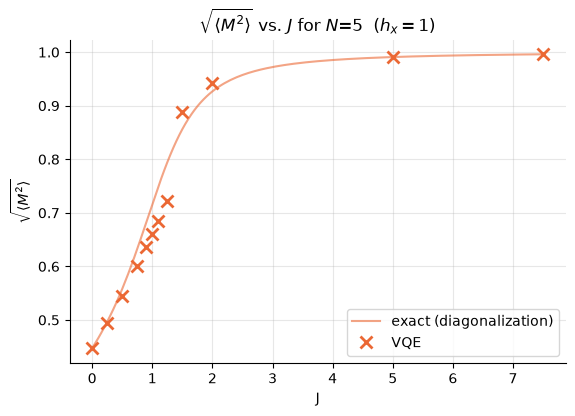

In [10]:
J_dense = np.linspace(0, 7.5, 151)
plt.plot(J_dense, [exact_rms_magnetization(N, J, h_x) for J in J_dense], color=SIZE_COLORS[5], lw=1.5, alpha=0.6,
         label="exact (diagonalization)")
plt.plot(J_list, np.sqrt(m2_list), ls="none", marker="x", ms=8, mew=2, color=SIZE_COLORS[5], label="VQE")
plt.xlabel("J")
plt.ylabel(r"$\sqrt{\langle M^2 \rangle}$")
plt.title(r"$\sqrt{\langle M^2 \rangle}$ vs. $J$ for $N$=" + str(N) + r"  ($h_x = 1$)")
plt.legend(loc="lower right")
plt.show()

$\sqrt{\langle M^2\rangle}$ grows from $1/\sqrt5 \approx 0.45$ at $J = 0$ (random spins) to almost 1 at large $J$ (ordered spins). It rises most steeply around $J \approx 1$, where we expect the transition.

The VQE points (crosses) follow the exact curve closely. The small differences around $J \approx 1$–$1.5$ come from the circuit: with only one layer of CNOTs it cannot represent the true ground state perfectly there. Even so, every VQE energy is within 2% of the exact one (see the table in Section 7).

For 5 qubits the change is gradual rather than abrupt. A truly sharp transition only exists for an infinitely long chain. So what happens when the chain gets longer?

## 7. Longer chains: the transition gets sharper

We now repeat the scan for $N = 4$, 6 and 8 qubits, with the same values of $J$. For every point we also compute the exact values, for comparison. This is a longer test, especially for $N=8$ expect long compute time.

In [11]:
sizes = [4, 6, 8]


def magnetization_scan(N, J_list, h_x=1.0):
    # The N = 5 scan above, for any N (starting angles from a generator seeded with N)
    ansatz = create_ansatz(N)
    M2 = magnetization_squared_op(N)
    rng = np.random.default_rng(N)
    out = {"runs": [], "E": [], "M2": [], "iterations": []}
    for J in J_list:
        H = ising_hamiltonian(N, J, h_x)
        runs = run_vqe(ansatz, H, rng)
        E, m2 = estimator.run([(ansatz, [H, M2], runs[0]["params"])]).result()[0].data.evs
        for key, value in zip(out, (runs, E, m2, runs[0]["iterations"])):
            out[key].append(value)
    return {key: (value if key == "runs" else np.array(value)) for key, value in out.items()}


scan = {5: {"runs": runs_5, "E": np.array(energy_list), "M2": np.array(m2_list),
            "iterations": np.array(iterations_list)}}
for N in sizes:
    scan[N] = magnetization_scan(N, J_list, h_x)

# exact ground-state energy and sqrt(<M^2>), for comparison
for N in scan:
    M2 = magnetization_squared_op(N)
    exact = [exact_ground_state(ising_hamiltonian(N, J, h_x)) for J in J_list]
    scan[N]["E0"] = np.array([e0 for e0, _ in exact])
    scan[N]["exact_rms"] = np.array([np.sqrt(Statevector(psi).expectation_value(M2).real) for _, psi in exact])

In [12]:
sizes = sorted(scan)
print("For each N: sqrt<M^2> from VQE, the exact value, and the relative energy error of VQE |E_VQE - E0| / |E0|\n")
print(" " * 6 + "".join(f"{'N = ' + str(N):^26}" for N in sizes))
print(f"{'J':>5} " + "".join(f"{'VQE':>8}{'exact':>8}{'error':>8}  " for N in sizes))
for k, J in enumerate(J_list):
    row = f"{J:5.2f} "
    for N in sizes:
        d = scan[N]
        error = abs(d["E"][k] - d["E0"][k]) / abs(d["E0"][k])
        row += f"{np.sqrt(d['M2'][k]):8.3f}{d['exact_rms'][k]:8.3f}{error:8.2%}  "
    print(row)

For each N: sqrt<M^2> from VQE, the exact value, and the relative energy error of VQE |E_VQE - E0| / |E0|

                N = 4                     N = 5                     N = 6                     N = 8           
    J      VQE   exact   error       VQE   exact   error       VQE   exact   error       VQE   exact   error  
 0.00    0.500   0.500   0.00%     0.447   0.447   0.00%     0.408   0.408   0.00%     0.354   0.354   0.00%  
 0.25    0.549   0.551   0.00%     0.494   0.497   0.00%     0.453   0.456   0.00%     0.394   0.397   0.00%  
 0.50    0.600   0.610   0.04%     0.545   0.558   0.06%     0.503   0.517   0.06%     0.441   0.457   0.07%  
 0.75    0.654   0.676   0.20%     0.600   0.633   0.26%     0.558   0.598   0.30%     0.494   0.543   0.35%  
 0.90    0.686   0.717   0.37%     0.635   0.682   0.50%     0.594   0.655   0.59%     0.530   0.612   0.71%  
 1.00    0.708   0.744   0.52%     0.660   0.716   0.70%     0.619   0.695   0.85%     0.555   0.664   1.05%  
 1.10

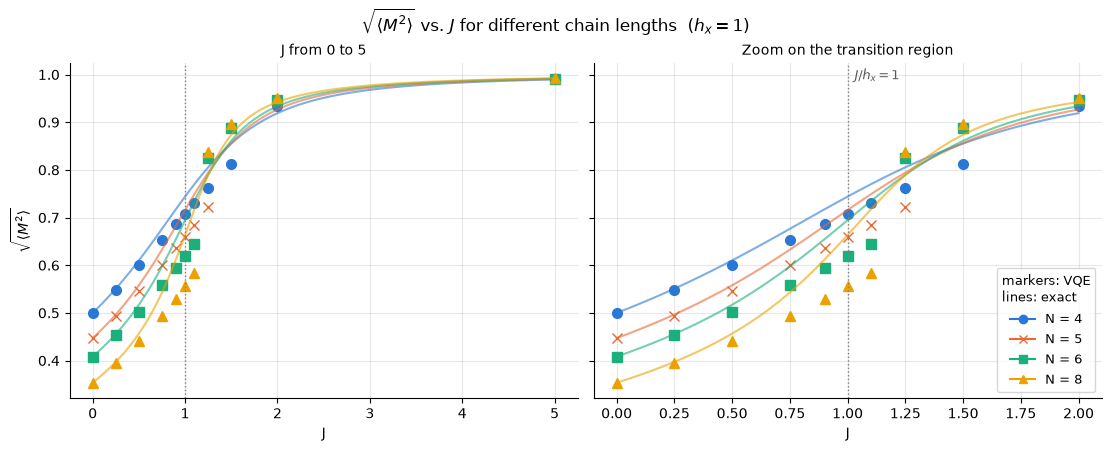

In [13]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, layout="constrained")
J_arr = np.array(J_list)
J_dense = np.linspace(0, 5, 101)
exact_dense = {N: np.array([exact_rms_magnetization(N, J, h_x) for J in J_dense]) for N in sizes}

for ax, J_max, title in zip(axes, (5.0, 2.0), ("J from 0 to 5", "Zoom on the transition region")):
    shown, dense = J_arr <= J_max, J_dense <= J_max
    for N in sizes:
        ax.plot(J_dense[dense], exact_dense[N][dense], color=SIZE_COLORS[N], lw=1.5, alpha=0.6)
        ax.plot(J_arr[shown], np.sqrt(scan[N]["M2"][shown]), ls="none", marker=SIZE_MARKERS[N], ms=7,
                color=SIZE_COLORS[N])
    ax.axvline(1.0, color="0.5", lw=1, ls=":")
    ax.set_xlabel("J")
    ax.set_title(title, fontsize=10)

axes[0].set_ylabel(r"$\sqrt{\langle M^2 \rangle}$")
axes[1].text(1.03, 0.98, r"$J/h_x = 1$", transform=axes[1].get_xaxis_transform(), color="0.35", fontsize=9, va="top")
handles = [Line2D([], [], color=SIZE_COLORS[N], marker=SIZE_MARKERS[N], lw=1.5, label=f"N = {N}") for N in sizes]
axes[1].legend(handles=handles, loc="lower right", title="markers: VQE\nlines: exact", fontsize=9, title_fontsize=9)
fig.suptitle(r"$\sqrt{\langle M^2 \rangle}$ vs. $J$ for different chain lengths  ($h_x = 1$)")
plt.show()

What the curves show:

- **At $J = 0$** every curve starts at $1/\sqrt N$ (0.500, 0.447, 0.408 and 0.354 for $N$ = 4, 5, 6 and 8): the spins are completely random.
- **The curves get steeper as $N$ grows.** Below the transition, longer chains give smaller values (at $J = 0.5$: 0.600, 0.545, 0.503, 0.441); above it, longer chains give larger values (at $J = 2$: 0.935, 0.942, 0.946, 0.950). This is how a phase transition shows up in finite systems: the change becomes sharper and sharper as the system grows, and for an infinitely long chain it becomes a sudden jump at $J/h_x = 1$.
- **VQE agrees well with the exact results** away from the transition. The differences are largest near $J \approx 1$, up to about 0.13 for $N = 8$, because the simple one-layer circuit cannot capture all the correlations between the spins there. Exercise 2 below explores how to improve this.

## 8. Going further: locating the transition with the Binder cumulant (optional)

The curves above show *that* the transition sharpens, but not exactly *where* it is. A standard trick, invented for computer simulations of magnets, is the **Binder cumulant**

$$U_4 = 1 - \frac{\langle M^4\rangle}{3\langle M^2\rangle^2}.$$

It is close to 0 when the spins are disordered and close to $2/3$ when they are ordered. At the transition it hardly depends on the length of the chain, so the curves for different $N$ **cross** there.

Here we compute $U_4$ exactly, for chains of up to 10 qubits (this takes a few seconds). On a quantum computer, $\langle M^2\rangle$ and $\langle M^4\rangle$ could be measured with the Estimator, just like the energy.

In [14]:
J_fine = np.linspace(0.25, 2.5, 91)
binder_sizes = [4, 6, 8, 10]

binder = {}
for N in binder_sizes:
    M = magnetization_op(N)
    M2 = (M @ M).simplify()
    M4 = (M2 @ M2).simplify()
    U = []
    for J in J_fine:
        psi = Statevector(exact_ground_state(ising_hamiltonian(N, J, h_x))[1])
        m2, m4 = psi.expectation_value(M2).real, psi.expectation_value(M4).real
        U.append(1 - m4 / (3 * m2**2))
    binder[N] = np.array(U)

# where the curves of consecutive sizes cross (linear interpolation of the difference)
crossings = []
for Na, Nb in zip(binder_sizes[:-1], binder_sizes[1:]):
    diff = binder[Nb] - binder[Na]
    k = np.where(np.sign(diff[:-1]) != np.sign(diff[1:]))[0][0]
    J_cross = J_fine[k] - diff[k] * (J_fine[k + 1] - J_fine[k]) / (diff[k + 1] - diff[k])
    crossings.append((Na, Nb, J_cross, np.interp(J_cross, J_fine, binder[Na])))
    print(f"U_4 for N = {Na} and N = {Nb} cross at J/h_x = {J_cross:.3f}")

U_4 for N = 4 and N = 6 cross at J/h_x = 1.178
U_4 for N = 6 and N = 8 cross at J/h_x = 1.086
U_4 for N = 8 and N = 10 cross at J/h_x = 1.051


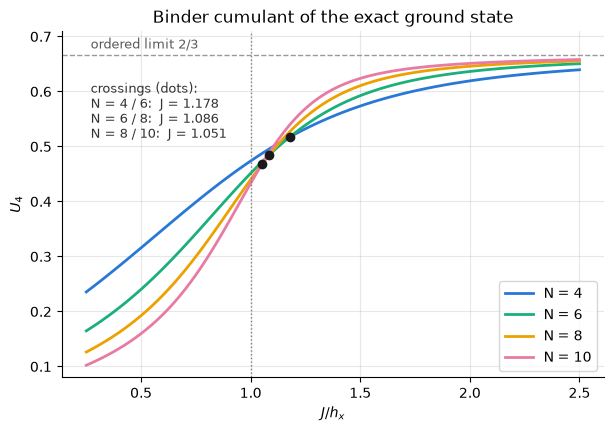

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for N in binder_sizes:
    ax.plot(J_fine, binder[N], color=SIZE_COLORS[N], lw=2, label=f"N = {N}")
for Na, Nb, J_cross, U_cross in crossings:
    ax.plot(J_cross, U_cross, "o", ms=6, color="0.1", zorder=3)
ax.axvline(1.0, color="0.5", lw=1, ls=":")
ax.axhline(2 / 3, color="0.6", lw=1, ls="--")
ax.text(0.27, 2 / 3 + 0.006, "ordered limit 2/3", ha="left", va="bottom", color="0.35", fontsize=9)
ax.set_ylim(0.08, 0.71)
ax.text(0.27, 0.62, "crossings (dots):\n" + "\n".join(f"N = {a} / {b}:  J = {x:.3f}" for a, b, x, _ in crossings),
        va="top", fontsize=9, color="0.2")
ax.set_xlabel(r"$J/h_x$")
ax.set_ylabel(r"$U_4$")
ax.set_title("Binder cumulant of the exact ground state")
ax.legend(loc="lower right")
plt.show()

The crossing points move towards $J/h_x = 1$ as the chains get longer: 1.18, 1.09 and 1.05 for the pairs 4/6, 6/8 and 8/10. With longer and longer chains they would converge to the exact value, $J/h_x = 1$.

## 9. What changes on a real quantum computer?

Everything quantum in this notebook goes through the Estimator, so the same code can run on real hardware by replacing `StatevectorEstimator` with the Estimator of a quantum computer (for IBM devices, from the `qiskit-ibm-runtime` package). A few things change:

- the circuit must first be **transpiled**: rewritten in the device's native gates and mapped onto its physical qubits;
- each expectation value is estimated from a finite number of measurements (**shots**), so it comes with statistical noise, on top of the noise of the device itself;
- optimizers that cope better with noisy measurements, such as SPSA or COBYLA, are then preferred to L-BFGS-B.

Measuring $M^2$ costs nothing extra: it contains only $Z$s, so it comes from the same measurements as the $ZZ$ terms of the energy.

## Summary

- The **Ising model in a transverse field** has two phases: ordered (spins aligned along $z$) when $J \gg h_x$, and disordered when $h_x \gg J$. For a long chain, the quantum phase transition between them is at $J/h_x = 1$.
- **VQE** finds the ground state by minimizing the energy of a parameterized circuit. Here: the hardware-efficient ansatz, energies and gradients from Qiskit's Estimator, and SciPy's L-BFGS-B optimizer started from three random points.
- The **size of the magnetization**, $\sqrt{\langle M^2\rangle}$, tracks the order. Its curves get steeper as the chain grows: the finite-size signature of the transition. The Binder cumulant locates it close to $J/h_x = 1$.

## Exercises

1. **Why not just $\langle M\rangle$?** The three VQE runs at $N = 5$, $J = 2$ are stored in `runs_5[J_list.index(2.0)]`. For each, measure $\langle M\rangle$ with `estimator.run([(ansatz_5, magnetization_op(5), run["params"])]).result()[0].data.evs`, and compare with $\sqrt{\langle M^2\rangle}$. What do you notice, and how does it relate to the "subtlety" in Section 5?
2. **A better circuit.** Give the ansatz two layers: repeat steps 2 and 3 of `create_ansatz` with new angles, or use Qiskit's `n_local(N, ["rz", "rx", "rz"], "cx", entanglement="linear", reps=2)` from `qiskit.circuit.library`. Does VQE get closer to the exact curve near $J = 1$? (The runs take longer.)
3. **A different field.** Set $h_x = 0.5$ and repeat the scan for $N = 5$. Where do you expect the transition now? Does the curve agree?
4. **A ring instead of a line.** Add the bond between the last and the first qubit to the Hamiltonian (and a CNOT between them in the ansatz). How do the results change?

## References

1. D. Pope and T. Shah, ["Seeing quantum phase transitions with quantum computers"](https://pennylane.ai/qml/demos/tutorial_quantum_phase_transitions), PennyLane demo (2025).
2. A. Kandala et al., "Hardware-efficient Variational Quantum Eigensolver for Small Molecules and Quantum Magnets", [arXiv:1704.05018](https://arxiv.org/abs/1704.05018) (2017).
3. S. Sachdev, *Quantum Phase Transitions*, 2nd ed., Cambridge University Press (2011).
4. P. Pfeuty, "The one-dimensional Ising model with a transverse field", Ann. Phys. **57**, 79 (1970).
5. K. Binder, "Finite size scaling analysis of Ising model block distribution functions", Z. Phys. B **43**, 119 (1981).